# 📊 E-Commerce Business Performance Analysis (Olist Dataset)

**Goal:** analyze sales performance, seasonality, product categories and customer satisfaction of Olist, a Brazilian e-commerce marketplace, to produce actionable business insights.

**Data:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle): ~100k orders from 2016 to 2018, spread over 9 relational tables.

**Methodology:** CRISP-DM
1. Business understanding
2. Data understanding
3. Data preparation
4. Exploratory analysis: sales trends, categories (Pareto), delivery vs. satisfaction, geography
5. Key insights and recommendations

## 1. Business understanding

Key business questions:
- What is the monthly sales trend, and is there a seasonal peak?
- Which product categories drive the revenue?
- Do delivery delays hurt customer satisfaction?
- Where are the customers located?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
DATA = "../data/"
OUT = "../output/visualizations/"


## 2. Data understanding

In [2]:
tables = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
dfs = {name: pd.read_csv(DATA + f) for name, f in tables.items()}
pd.DataFrame({name: [len(df), df.shape[1]] for name, df in dfs.items()}, index=["rows", "columns"]).T

,rows,columns
orders,99441,8
items,112650,7
products,32951,9
reviews,99224,7
customers,99441,5
payments,103886,5
sellers,3095,4
translation,71,2


In [3]:
orders = dfs["orders"]
for col in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[col] = pd.to_datetime(orders[col])
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

## 3. Data preparation

We keep **delivered** orders only, and attach items, English category names, customers and reviews.

In [4]:
delivered = orders[orders["order_status"] == "delivered"].copy()

products = dfs["products"].merge(dfs["translation"], on="product_category_name", how="left")
products["category"] = products["product_category_name_english"].fillna("unknown")

items = (dfs["items"]
         .merge(delivered[["order_id", "order_purchase_timestamp", "customer_id"]], on="order_id")
         .merge(products[["product_id", "category"]], on="product_id", how="left")
         .merge(dfs["customers"][["customer_id", "customer_state"]], on="customer_id", how="left"))
items["month"] = items["order_purchase_timestamp"].dt.to_period("M")

print(f"Delivered orders: {delivered['order_id'].nunique():,}")
print(f"Order items: {len(items):,}")
print(f"Revenue (product price, excl. freight): R$ {items['price'].sum():,.0f}")

Delivered orders: 96,478
Order items: 110,197
Revenue (product price, excl. freight): R$ 13,221,498


## 4. Exploratory analysis

### 4.1 Monthly sales trend

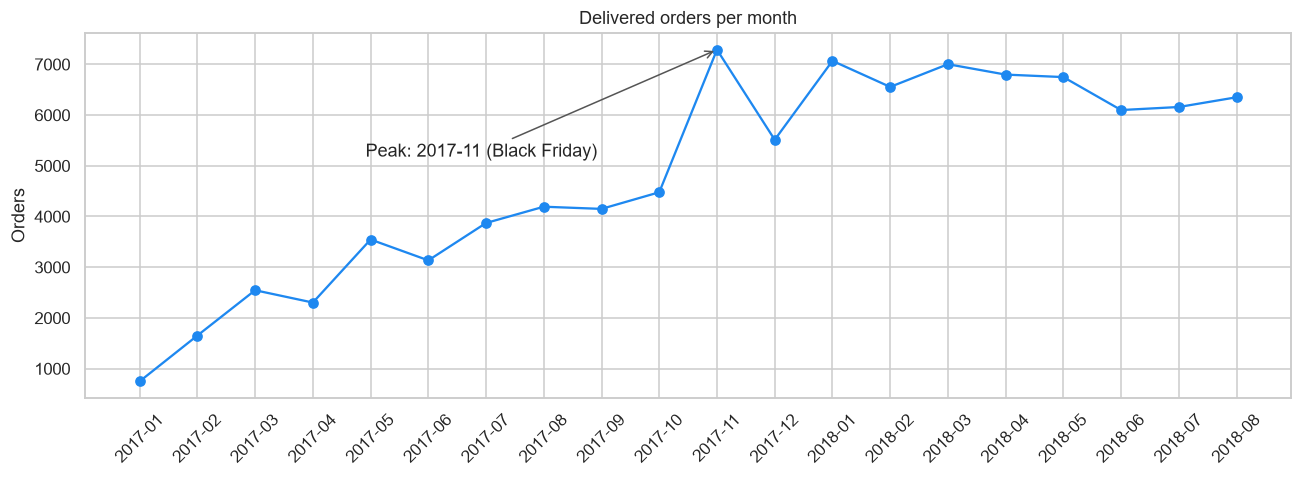

Peak month: 2017-11 with 7,289 orders (+63% vs October 2017)
Revenue growth Jan-Aug 2018 vs Jan-Aug 2017: +141%


In [5]:
monthly = items.groupby("month").agg(orders=("order_id", "nunique"), revenue=("price", "sum"))
# 2016 and the last months of 2018 are incomplete: we analyze Jan 2017 - Aug 2018
monthly = monthly.loc["2017-01":"2018-08"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index.astype(str), monthly["orders"], marker="o", color="#1e88f0")
peak = monthly["orders"].idxmax()
ax.annotate(f"Peak: {peak} (Black Friday)", xy=(str(peak), monthly.loc[peak, "orders"]),
            xytext=(-230, -70), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_title("Delivered orders per month")
ax.set_ylabel("Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT + "monthly_orders.png", bbox_inches="tight")
plt.show()

nov, oct_ = monthly.loc["2017-11", "orders"], monthly.loc["2017-10", "orders"]
print(f"Peak month: {peak} with {monthly.loc[peak, 'orders']:,} orders ({nov / oct_ - 1:+.0%} vs October 2017)")
growth = monthly.loc["2018-01":"2018-08", "revenue"].sum() / monthly.loc["2017-01":"2017-08", "revenue"].sum() - 1
print(f"Revenue growth Jan-Aug 2018 vs Jan-Aug 2017: {growth:+.0%}")

In [6]:
black_friday = items[items["order_purchase_timestamp"].dt.date == pd.Timestamp("2017-11-24").date()]["order_id"].nunique()
daily_avg_nov = items[items["month"] == pd.Period("2017-11")].groupby(items["order_purchase_timestamp"].dt.date)["order_id"].nunique().median()
print(f"Orders on Black Friday (24 Nov 2017): {black_friday:,} vs a median of {daily_avg_nov:.0f} per day in November")

Orders on Black Friday (24 Nov 2017): 1,147 vs a median of 183 per day in November


### 4.2 Product categories: Pareto analysis

72 categories
8 categories (11%) make 50% of revenue; 18 categories (25%) make 80%
The top 20% of categories account for 74% of revenue


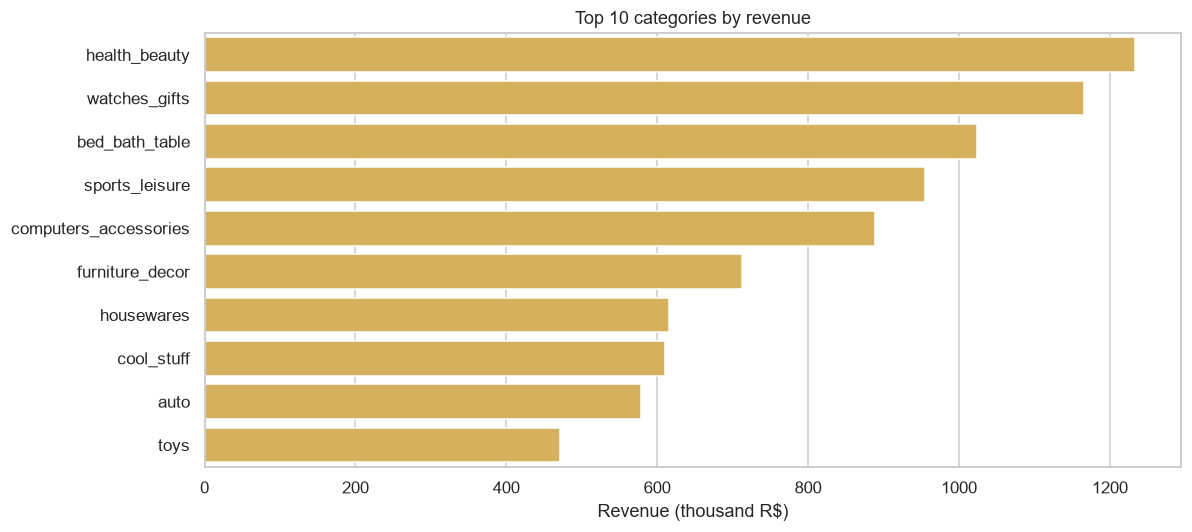

In [7]:
cat = items.groupby("category")["price"].sum().sort_values(ascending=False)
cum_share = cat.cumsum() / cat.sum()
n = len(cat)
n_50 = (cum_share < 0.5).sum() + 1
n_80 = (cum_share < 0.8).sum() + 1
top20 = cat.head(int(round(n * 0.2))).sum() / cat.sum()
print(f"{n} categories")
print(f"{n_50} categories ({n_50 / n:.0%}) make 50% of revenue; {n_80} categories ({n_80 / n:.0%}) make 80%")
print(f"The top 20% of categories account for {top20:.0%} of revenue")

top = cat.head(10)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=top.values / 1e3, y=top.index, ax=ax, color="#e9b949")
ax.set_title("Top 10 categories by revenue")
ax.set_xlabel("Revenue (thousand R$)"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(OUT + "top_categories.png", bbox_inches="tight")
plt.show()

### 4.3 Delivery delays vs. customer satisfaction

In [8]:
reviews = dfs["reviews"].drop_duplicates("order_id")[["order_id", "review_score"]]
deliv = delivered.dropna(subset=["order_delivered_customer_date"]).merge(reviews, on="order_id", how="inner")
deliv["delay_days"] = (deliv["order_delivered_customer_date"] - deliv["order_estimated_delivery_date"]).dt.days
deliv["late"] = deliv["delay_days"] > 0

summary = deliv.groupby("late").agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                     share_1_2_stars=("review_score", lambda s: (s <= 2).mean()))
summary.index = ["On time", "Late"]
print(summary.round(2))
print(f"\nShare of late deliveries: {deliv['late'].mean():.1%}")
low = deliv[deliv["review_score"] <= 2]
print(f"Late deliveries represent {low['late'].mean():.0%} of 1-2 star reviews (vs {deliv['late'].mean():.0%} of all orders)")

         orders  avg_score  share_1_2_stars
On time   89443       4.29             0.09
Late       6381       2.27             0.62

Share of late deliveries: 6.7%
Late deliveries represent 32% of 1-2 star reviews (vs 7% of all orders)


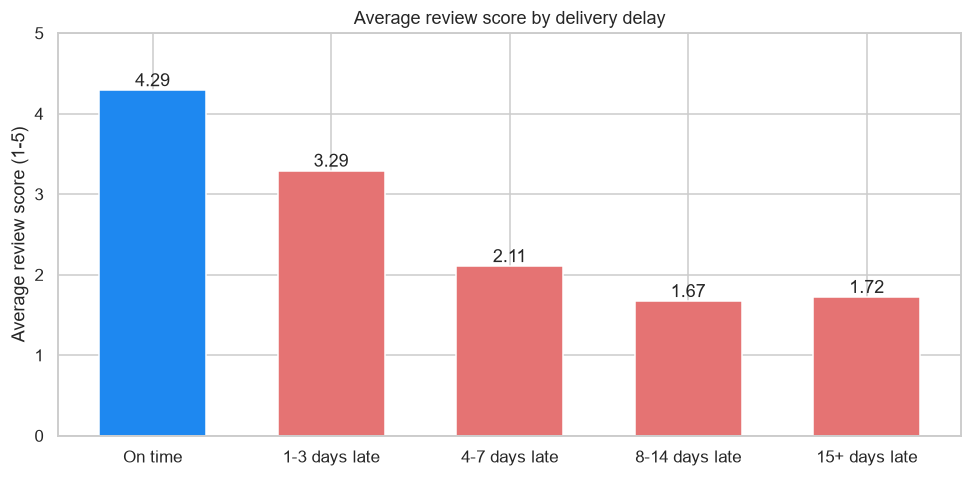

In [9]:
bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ["On time", "1-3 days late", "4-7 days late", "8-14 days late", "15+ days late"]
deliv["delay_bucket"] = pd.cut(deliv["delay_days"], bins=bins, labels=labels)
by_bucket = deliv.groupby("delay_bucket", observed=True)["review_score"].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(by_bucket.index.astype(str), by_bucket.values, color=["#1e88f0"] + ["#e57373"] * 4, width=0.6)
for i, v in enumerate(by_bucket.values):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5)
ax.set_title("Average review score by delivery delay")
ax.set_xlabel(""); ax.set_ylabel("Average review score (1-5)")
plt.tight_layout()
plt.savefig(OUT + "delay_vs_review.png", bbox_inches="tight")
plt.show()

### 4.4 Geography

Top state: SP with 38% of revenue; top 3 states (SP, RJ, MG...) = 63%


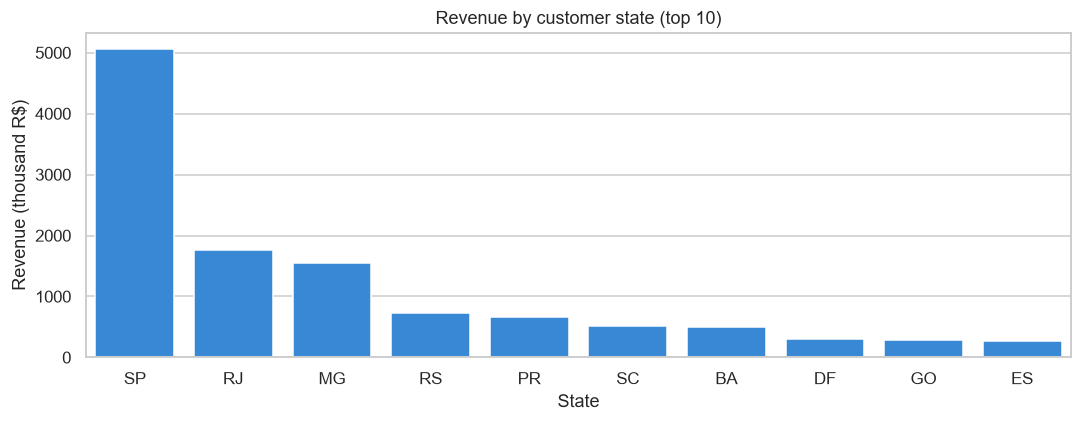

In [10]:
state = items.groupby("customer_state")["price"].sum().sort_values(ascending=False)
share_sp = state.iloc[0] / state.sum()
share_top3 = state.head(3).sum() / state.sum()
print(f"Top state: {state.index[0]} with {share_sp:.0%} of revenue; top 3 states (SP, RJ, MG...) = {share_top3:.0%}")

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=state.head(10).index, y=state.head(10).values / 1e3, ax=ax, color="#1e88f0")
ax.set_title("Revenue by customer state (top 10)")
ax.set_xlabel("State"); ax.set_ylabel("Revenue (thousand R$)")
plt.tight_layout()
plt.savefig(OUT + "revenue_by_state.png", bbox_inches="tight")
plt.show()

## 5. Key insights & recommendations

1. **Strong growth and seasonality:** activity grows steadily through 2017 and peaks in **November 2017 with Black Friday**. → Plan stock, logistics capacity and marketing budget ahead of November.
2. **Revenue is concentrated:** a small share of categories drives most of the revenue (see Pareto results above). → Focus seller acquisition and promotions on the leading categories.
3. **Late deliveries destroy satisfaction:** late orders get a much lower average score, and they are heavily over-represented among 1-2 star reviews. → Improve delivery-date estimates and monitor late carriers/sellers: it is the most direct lever on customer satisfaction.
4. **Geographic concentration:** São Paulo state alone generates a large share of revenue. → Prioritize logistics performance in the South-East, and test regional campaigns to grow other states.